# Group 7 – Congestion pricing: tests of H1 to H6

**How to use:** run the cells from top to bottom, one at a time. Each code cell has a short note above it explaining what it does and why.

**Files needed (in the folder set as `DATA`):** `summary_zone_daily.csv`, `summary_pickups_by_region_hour.csv`, `summary_flows_region_pairs.csv`, `summary_daily_by_region.csv`.
**Optional:** `out/zone_flags.csv` (used for the distance rings and borough checks; those cells skip themselves if it is missing).

**Design in one paragraph:** treated = CBD zones, control = matched outside non-airport zones, pre = 1 Oct 2024 – 4 Jan 2025, post = 5 Jan – 31 Mar 2025. Count outcomes use Poisson regression with zone and date fixed effects and zone-clustered standard errors; ratio outcomes use weighted least squares with the same fixed effects.

**Holiday handling (important):** in a test run, the CBD moved very differently from other zones around Thanksgiving and Christmas/New Year (the 29 Dec – 4 Jan week is especially quiet in the CBD). Using those weeks as "normal" pre-policy data distorts every before/after comparison. So the **main sample leaves out 27 Nov – 1 Dec and 20 Dec – 4 Jan** (`MAIN_RANGES`), and the version with all days is shown as a sensitivity check. The event study uses all days but takes clean November weeks as its baseline.

## 0. Setup

In [1]:
# Imports and settings. Change the settings here and everything below follows.
import os, warnings
import numpy as np
import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt
from scipy.spatial.distance import cdist, jensenshannon
from statsmodels.stats.multitest import multipletests

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.options.display.float_format = "{:,.3f}".format

DATA = "."                          # folder that holds the CSV files
FLAGS_PATH = "zone_flags.csv"   # optional file from the zones stage

START = pd.Timestamp("2025-01-05")  # policy start (Jan 1-4 count as pre-policy)
D1_FROM, D1_TO = "2024-10-01", "2025-03-31"      # main sample
PRE_FROM, PRE_TO = "2024-10-01", "2024-12-31"    # full pre window (used only for the volume filter label)

# holiday windows that distort the CBD (Thanksgiving, Christmas / New Year) are left out of the main sample
FULL_RANGES = [(D1_FROM, D1_TO)]                                              # every day
PRE_RANGES = [(D1_FROM, "2024-11-26"), ("2024-12-02", "2024-12-19")]          # clean pre-policy days
MAIN_RANGES = PRE_RANGES + [("2025-01-05", D1_TO)]                            # clean pre + post
REF_WEEKS = [-9, -8, -7]          # event study baseline = three clean November weeks
HOLIDAY_WEEKS = [-6, -2, -1]      # Thanksgiving and Christmas/New Year weeks (shown, but not part of the pre-trend test)
YOY_PRE, YOY_POST = ["2024-02", "2024-03"], ["2025-02", "2025-03"]           # same months a year apart (used for the hourly/charge tables)
SERVICES = ["yellow", "fhvhv"]
MIN_PRE_MEAN = 5     # a zone needs >= 5 trips/day on average in the pre window to be used
K_MATCH = 3          # nearest control zones per treated zone
N_PLACEBO = 10       # number of random placebo groups (raise to 100 for the final run)
SEED = 42
rng = np.random.default_rng(SEED)

os.makedirs("results", exist_ok=True)
os.makedirs("figures", exist_ok=True)
rows = []            # every main result is collected here and used for the multiple-testing table at the end

C:\Users\yugsa\anaconda3\Lib\site-packages\pandas\core\computation\expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


## 1. Load the zone-daily file
One row = service × zone × date × period (peak / offpeak). Zones with no trips on a day are missing from the file, so we fill them with zeros later. The `*_strict` columns are blank when a zone-day had no clean trips, so we set those blanks to 0.

In [2]:
z = pd.read_csv(f"{DATA}/summary_zone_daily.csv", parse_dates=["date"])
strict_cols = [c for c in z.columns if c.endswith("_strict")]
z[strict_cols] = z[strict_cols].fillna(0)
print(z.shape)
z.head()

(260709, 13)


,service,date,zone,region,is_airport,period,trips_counts,trips_strict,secs_strict,miles_strict,base_fare_strict,cbd_fee_strict,n_fee_trips_strict
0,fhvhv,2024-02-01,3,outside,False,offpeak,217,217.000,"177,769.000","1,107.232","4,055.410",0.000,0.000
1,fhvhv,2024-02-01,3,outside,False,peak,1259,"1,258.000","1,199,547.000","5,164.006","23,276.200",0.000,0.000
2,fhvhv,2024-02-01,4,cbd,False,offpeak,512,512.000,"533,927.000","2,326.917","10,983.790",0.000,0.000
3,fhvhv,2024-02-01,4,cbd,False,peak,1402,"1,402.000","1,663,451.000","5,880.567","33,061.440",0.000,0.000
4,fhvhv,2024-02-01,5,outside,False,offpeak,15,15.000,"12,764.000",103.216,316.540,0.000,0.000


In [3]:
# Which months and how many zones do we have per service?
print(z.assign(ym=z.date.dt.strftime("%Y-%m")).groupby(["service", "ym"]).agg(rows=("zone", "size"), zones=("zone", "nunique")).unstack(0))

          rows              zones             
service  fhvhv green yellow fhvhv green yellow
ym                                            
2024-02  14926  4127  11086   262   207    254
2024-03  15969  4322  12588   261   219    259
2024-10  15989  4312  13133   262   234    261
2024-11  15451  3976  12904   262   222    260
2024-12  15956  4179  13031   262   218    258
2025-01  15958  3833  13300   262   212    261
2025-02  14422  3738  12646   263   226    257
2025-03  15960  4514  14389   262   231    260


## 2. Define the groups
`region` and `is_airport` come from the zone flags the script already attached. We keep the CBD as treated, the buffer for H2, and use outside non-airport zones as the pool for controls. Unknown zones and airports are left out of the causal comparisons.

In [4]:
zinfo = z[["zone", "region", "is_airport"]].drop_duplicates("zone").set_index("zone")
cbd_zones = list(zinfo.index[zinfo.region == "cbd"])
buffer_zones = list(zinfo.index[zinfo.region == "buffer"])
pool_zones = list(zinfo.index[(zinfo.region == "outside") & (~zinfo.is_airport)])
print("CBD:", len(cbd_zones), "| buffer:", len(buffer_zones), "| control pool:", len(pool_zones))

# average trips per day in the clean pre window, per service and zone
pre = pd.concat([z[(z.date >= a) & (z.date <= b)] for a, b in PRE_RANGES])   # clean pre-policy days only
n_pre_days = pre.date.nunique()
pre_mean = (pre.groupby(["service", "zone"]).trips_counts.sum() / n_pre_days).unstack(0).fillna(0)

# zones busy enough to be informative, per service
ok = {s: set(pre_mean.index[pre_mean[s] >= MIN_PRE_MEAN]) for s in SERVICES}
for s in SERVICES:
    print(s, "| treated usable:", len([x for x in cbd_zones if x in ok[s]]),
          "| buffer usable:", len([x for x in buffer_zones if x in ok[s]]),
          "| controls usable:", len([x for x in pool_zones if x in ok[s]]))

CBD: 39 | buffer: 7 | control pool: 212
yellow | treated usable: 38 | buffer usable: 7 | controls usable: 152
fhvhv | treated usable: 38 | buffer usable: 7 | controls usable: 209


## 3. Quick look before any model
Daily CBD trips relative to outside trips (log ratio, shifted so the pre-policy average is 0), from the small region file. A drop after the red line is what H1 predicts. The "outside" line here still includes airports, so this is only a first look.

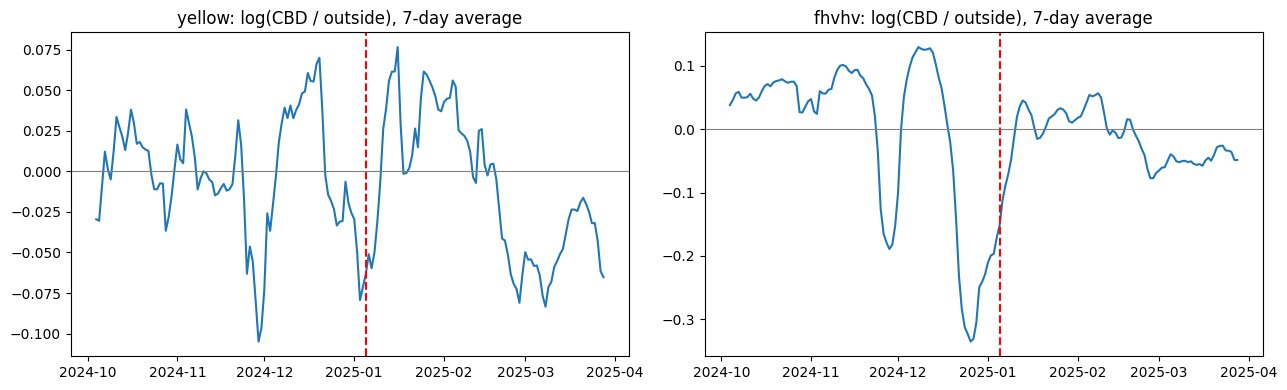

In [5]:
d = pd.read_csv(f"{DATA}/summary_daily_by_region.csv", parse_dates=["date"])
d = d[(d.dataset == "counts") & (d.date >= D1_FROM) & (d.date <= D1_TO)]

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, s in zip(axes, SERVICES):
    w = d[d.service == s].pivot_table(index="date", columns="region", values="trips", aggfunc="sum")
    r = np.log(w["cbd"] / w["outside"])
    r = r - r[r.index < START].mean()
    ax.plot(r.index, r.rolling(7, center=True).mean())
    ax.axvline(START, color="red", ls="--")
    ax.axhline(0, color="grey", lw=0.8)
    ax.set_title(f"{s}: log(CBD / outside), 7-day average")
plt.tight_layout()
plt.savefig("figures/quicklook_cbd_vs_outside.png", dpi=150)
plt.show()

#### This dip in taxi usage are during Holiday season (New Years), where people do not travel much and stay with their families 

## 4. Helper functions (defined once, used in every test)
- `make_panel`: builds a zone × date table and fills missing days with zeros
- `did_panel`: adds the treated / post columns
- `fit_poisson` / `fit_wls`: the two model types, both with zone and date fixed effects and zone-clustered errors
- `tidy`: turns a fitted model into one clean result row (percent effect and 95% CI)
- `match_controls`: picks control zones that looked like the treated zones before the policy

In [6]:
VAL = ["trips_counts", "trips_strict", "secs_strict", "miles_strict",
       "base_fare_strict", "cbd_fee_strict", "n_fee_trips_strict"]


def make_panel(service, zones, ranges, period=None):
    """zone x date table for one service; every zone-day in the date ranges is present (zeros filled)."""
    s = z[z.service == service]
    keep = np.zeros(len(s), dtype=bool)
    for a, b in ranges:
        keep |= ((s.date >= a) & (s.date <= b)).values
    s = s[keep]
    dates = np.sort(s.date.unique())
    if period:
        s = s[s.period == period]
    s = s[s.zone.isin(zones)]
    g = s.groupby(["zone", "date"])[VAL].sum()
    idx = pd.MultiIndex.from_product([sorted(zones), dates], names=["zone", "date"])
    return g.reindex(idx, fill_value=0).reset_index()


def post_d1(dates):
    return (dates >= START).astype(int)


def post_yoy(dates):
    return (dates.dt.year == 2025).astype(int)


def did_panel(service, treated, controls, ranges, post_rule=post_d1, period=None):
    df = make_panel(service, list(treated) + list(controls), ranges, period)
    df["treat"] = df.zone.isin(treated).astype(int)
    df["post"] = post_rule(df.date)
    df["treat_post"] = df.treat * df.post
    return df


def fe_dummies(df, group=None):
    """zone and date fixed effects (as dummy columns). With group=, they are specific to that group (e.g. service)."""
    zk = df.zone.astype(str)
    dk = df.date.dt.strftime("%Y%m%d")
    if group:
        zk, dk = zk + "_" + df[group], dk + "_" + df[group]
    A = pd.get_dummies(zk, prefix="z", drop_first=True, dtype=float)
    B = pd.get_dummies(dk, prefix="d", drop_first=True, dtype=float)
    return pd.concat([A, B], axis=1)


def fit_poisson(df, terms, y="trips_counts", group=None):
    df = df.reset_index(drop=True)
    X = sm.add_constant(pd.concat([df[terms].astype(float), fe_dummies(df, group)], axis=1))
    groups = pd.factorize(df.zone)[0]
    return sm.GLM(df[y].astype(float), X, family=sm.families.Poisson()).fit(
        cov_type="cluster", cov_kwds={"groups": groups})


def fit_wls(df, y, terms, weight, group=None):
    df = df.reset_index(drop=True)
    X = sm.add_constant(pd.concat([df[terms].astype(float), fe_dummies(df, group)], axis=1))
    groups = pd.factorize(df.zone)[0]
    return sm.WLS(df[y], X, weights=df[weight]).fit(cov_type="cluster", cov_kwds={"groups": groups})


def tidy(res, term, label, n_cl, pct=True):
    """one result row. pct=True: coefficient is a log change -> show as % change."""
    b, se, p = res.params[term], res.bse[term], res.pvalues[term]
    lo, hi = res.conf_int().loc[term]
    out = dict(label=label, coef=b, se=se, p=p, ci_low=lo, ci_high=hi, n=int(res.nobs), clusters=n_cl)
    if pct:
        out.update(pct=np.expm1(b) * 100, pct_low=np.expm1(lo) * 100, pct_high=np.expm1(hi) * 100)
    return out


def match_controls(service, treated, pool, k=K_MATCH):
    """For every treated zone, pick the k control zones with the most similar PRE-policy behaviour.
    Similarity = level of trips, trend, weekend share and peak share (all measured on clean pre-policy days only)."""
    t = [x for x in treated if x in ok[service]]
    c = [x for x in pool if x in ok[service]]
    p = make_panel(service, t + c, PRE_RANGES)
    p["lg"] = np.log1p(p.trips_counts)
    wide = p.pivot(index="zone", columns="date", values="lg")
    f = pd.DataFrame(index=wide.index)
    f["log_mean"] = wide.mean(axis=1)
    f["slope"] = np.polyfit(np.arange(wide.shape[1]), wide.values.T, 1)[0]
    p["wknd"] = p.date.dt.dayofweek >= 5
    f["weekend_share"] = p[p.wknd].groupby("zone").trips_counts.sum() / p.groupby("zone").trips_counts.sum()
    pz = pre[(pre.service == service) & (pre.zone.isin(t + c))]
    pp = pz.pivot_table(index="zone", columns="period", values="trips_counts", aggfunc="sum").fillna(0)
    f["peak_share"] = pp["peak"] / (pp["peak"] + pp["offpeak"])
    f = f.fillna(f.mean())
    Z = (f - f.mean()) / f.std()
    dist = cdist(Z.loc[t].values, Z.loc[c].values)
    nearest = np.argsort(dist, axis=1)[:, :k]
    matched = sorted(set(np.array(c)[nearest.ravel()]))
    return t, matched, f


print("helpers ready")

helpers ready


# H1 – Demand shift
**Question:** did pickups inside the priced zone fall relative to comparable outside areas?
**Data:** `summary_zone_daily.csv` → `trips_counts`, `region`, `is_airport`, `date`, `zone`.
**Method:** Poisson DiD, `treat × post` with zone and date fixed effects, errors clustered by zone. The reported number is the % change in CBD pickups relative to controls.

### H1 step 1 – pick matched control zones
For each service, each treated (CBD) zone gets its 3 nearest outside zones based only on clean pre-policy behaviour (Oct – early Dec 2024, holidays excluded). The balance table shows how much more alike treated and matched zones are than treated vs all outside zones (smaller numbers = better balance).

In [7]:
setup = {}
for s in SERVICES:
    t, m, f = match_controls(s, cbd_zones, pool_zones)
    allc = [x for x in pool_zones if x in ok[s]]
    setup[s] = dict(treated=t, matched=m, all_ctrl=allc, feats=f)
    sd = f.loc[t + allc].std()
    bal = pd.DataFrame({
        "treated": f.loc[t].mean(),
        "all_outside": f.loc[allc].mean(),
        "matched": f.loc[m].mean(),
    })
    bal["std_diff_all"] = (bal.treated - bal.all_outside) / sd
    bal["std_diff_matched"] = (bal.treated - bal.matched) / sd
    print(f"\n{s}: {len(t)} treated zones, {len(m)} matched controls (of {len(allc)} usable outside zones)")
    print(bal)


yellow: 38 treated zones, 31 matched controls (of 152 usable outside zones)
               treated  all_outside  matched  std_diff_all  std_diff_matched
log_mean         7.106        3.288    5.063         1.877             1.004
slope            0.002        0.001    0.002         0.023            -0.105
weekend_share    0.310        0.288    0.337         0.227            -0.289
peak_share       0.699        0.759    0.725        -0.467            -0.200

fhvhv: 38 treated zones, 51 matched controls (of 209 usable outside zones)
               treated  all_outside  matched  std_diff_all  std_diff_matched
log_mean         8.258        7.163    7.985         0.887             0.221
slope            0.002        0.002    0.002         0.272             0.123
weekend_share    0.299        0.289    0.313         0.211            -0.293
peak_share       0.665        0.749    0.703        -1.261            -0.568


### H1 step 2 – main result
One regression per service. `pct` is the percent change in CBD pickups after 5 Jan 2025 relative to the matched controls.

In [8]:
h1 = []
for s in SERVICES:
    df = did_panel(s, setup[s]["treated"], setup[s]["matched"], MAIN_RANGES)
    res = fit_poisson(df, ["treat_post"])
    r = tidy(res, "treat_post", f"H1 {s} (CBD pickups, matched controls)", df.zone.nunique())
    h1.append(r)
    rows.append(dict(r, hyp="H1", service=s, primary=True))
pd.DataFrame(h1)[["label", "pct", "pct_low", "pct_high", "p", "n", "clusters"]]

,label,pct,pct_low,pct_high,p,n,clusters
0,"H1 yellow (CBD pickups, matched controls)",-0.596,-7.623,6.965,0.873,11109,69
1,"H1 fhvhv (CBD pickups, matched controls)",-7.233,-8.421,-6.030,0.000,14329,89


### H1 step 3 – event study and parallel-trends check
Instead of one before/after number we estimate one effect per week, relative to three clean November weeks (weeks −9 to −7). If treated and control zones were moving together before the policy, the pre-policy weeks should hover around zero. The Wald test checks that the non-holiday pre-policy weeks are jointly zero (a small p-value would warn that trends already differed). Holiday weeks are drawn in grey because the CBD behaves differently then for reasons unrelated to the policy.

**How to read it:** with millions of HVFHV trips, even a ±3% weekly wiggle is "statistically significant", so the Wald test will often reject. Look at the *size* of the pre-policy wiggles (printed below: "largest non-holiday pre-week deviation") and compare it with the post-policy effect. You want the pre-policy weeks to stay within a few percent and the post-policy weeks to sit clearly beyond them.

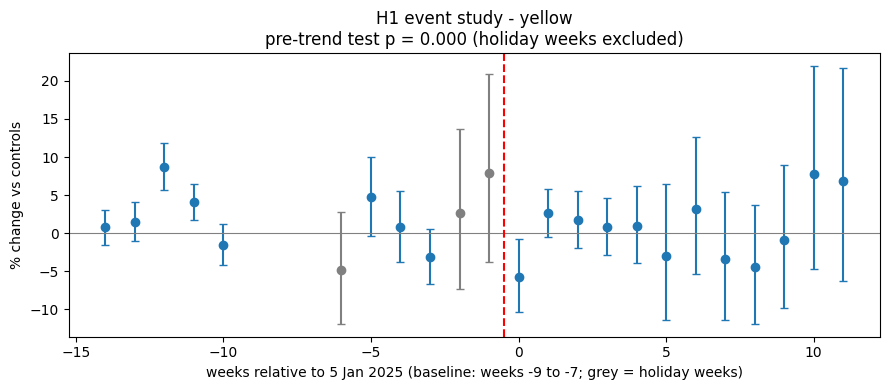

yellow: pre-trend Wald p = 4.52e-09 | largest non-holiday pre-week deviation = 8.7% | average post-week effect = 0.6%


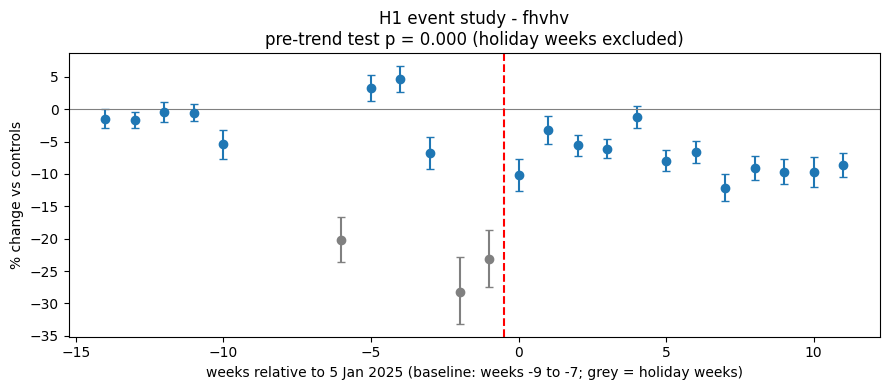

fhvhv: pre-trend Wald p = 7.46e-30 | largest non-holiday pre-week deviation = 6.8% | average post-week effect = -7.5%


In [9]:
def event_study(df, plot_title=None, fname=None):
    """One effect per week (relative to the clean-November baseline weeks), plus a joint test that the
    pre-policy weeks are zero. Holiday weeks are drawn in grey and left out of that joint test."""
    df = df.copy()
    df["wk"] = (df.date - START).dt.days // 7
    df = df[df.wk.map(df.groupby("wk").date.nunique()) >= 3].copy()   # drop weeks with fewer than 3 days of data (e.g. the last 2 days of March)
    ks = [k for k in sorted(df.wk.unique()) if k not in REF_WEEKS]
    names = {k: f"ev_{'m' if k < 0 else 'p'}{abs(k)}" for k in ks}
    for k, nm in names.items():
        df[nm] = ((df.treat == 1) & (df.wk == k)).astype(float)
    res = fit_poisson(df, list(names.values()))
    leads = [nm for k, nm in names.items() if k < 0 and k not in HOLIDAY_WEEKS]
    R = np.zeros((len(leads), len(res.params)))
    for i, nm in enumerate(leads):
        R[i, list(res.params.index).index(nm)] = 1
    w = res.wald_test(R, use_f=False, scalar=True)
    pretrend_p = float(w.pvalue)
    ci = res.conf_int()
    est = pd.DataFrame({
        "week": list(names.keys()),
        "pct": [np.expm1(res.params[nm]) * 100 for nm in names.values()],
        "lo": [np.expm1(ci.loc[nm, 0]) * 100 for nm in names.values()],
        "hi": [np.expm1(ci.loc[nm, 1]) * 100 for nm in names.values()],
    })
    if plot_title:
        plt.figure(figsize=(9, 4))
        for _, r in est.iterrows():
            col = "grey" if r.week in HOLIDAY_WEEKS else "tab:blue"
            plt.errorbar(r.week, r.pct, yerr=[[r.pct - r.lo], [r.hi - r.pct]], fmt="o", capsize=3, color=col)
        plt.axhline(0, color="grey", lw=0.8)
        plt.axvline(-0.5, color="red", ls="--")
        plt.xlabel("weeks relative to 5 Jan 2025 (baseline: weeks -9 to -7; grey = holiday weeks)")
        plt.ylabel("% change vs controls")
        plt.title(f"{plot_title}\npre-trend test p = {pretrend_p:.3f} (holiday weeks excluded)")
        plt.tight_layout()
        if fname:
            plt.savefig(fname, dpi=150)
        plt.show()
    return est, pretrend_p


pretrend = {}
for s in SERVICES:
    df = did_panel(s, setup[s]["treated"], setup[s]["matched"], FULL_RANGES)   # all days, so every week is visible
    est, p = event_study(df, f"H1 event study - {s}", f"figures/h1_event_{s}.png")
    pretrend[s] = p
    hol = est.week.isin(HOLIDAY_WEEKS)
    pre_dev = est[(est.week < 0) & ~hol].pct.abs().max()          # biggest non-holiday pre-policy wiggle
    post_avg = est[(est.week >= 0) & (est.week <= 11)].pct.mean()  # average of post-policy weeks 0-11
    print(f"{s}: pre-trend Wald p = {p:.3g} | largest non-holiday pre-week deviation = {pre_dev:.1f}% | average post-week effect = {post_avg:.1f}%")

### H1 step 4 – placebo tests
**(a) Placebo dates:** use only clean pre-policy data and pretend the policy started on 27 Oct or 10 Nov. A real policy effect should not show up here, so estimates should be close to zero.
**(b) Placebo groups:** keep the real policy date but pretend a random set of outside zones was treated. The real CBD effect should sit well outside the spread of these fake effects.

In [10]:
plc = []
for s in SERVICES:
    for fake in ["2024-10-27", "2024-11-10"]:
        df = did_panel(s, setup[s]["treated"], setup[s]["matched"], PRE_RANGES,
                       post_rule=lambda dts, f=fake: (dts >= f).astype(int))
        res = fit_poisson(df, ["treat_post"])
        r = tidy(res, "treat_post", f"{s} placebo date {fake}", df.zone.nunique())
        plc.append(r)
pd.DataFrame(plc)[["label", "pct", "pct_low", "pct_high", "p"]]

,label,pct,pct_low,pct_high,p
0,yellow placebo date 2024-10-27,-4.541,-6.923,-2.097,0.000
1,yellow placebo date 2024-11-10,-2.987,-5.997,0.119,0.059
2,fhvhv placebo date 2024-10-27,0.734,-0.350,1.830,0.185
3,fhvhv placebo date 2024-11-10,2.931,1.547,4.334,0.000


yellow: share of placebo effects at least as large as the real one = 1.000
fhvhv: share of placebo effects at least as large as the real one = 0.000


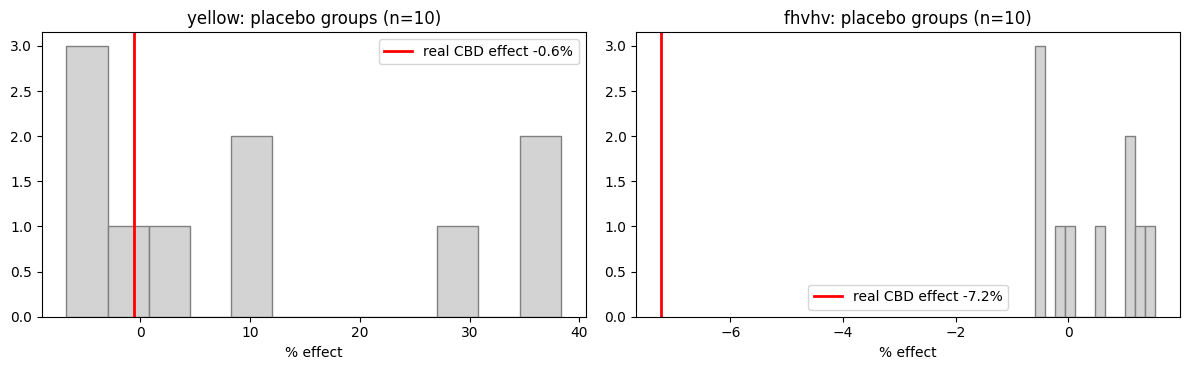

In [11]:
# Placebo groups: random sets of outside zones play the role of "treated" (this can take a few minutes)
placebo_dist = {}
for s in SERVICES:
    pool = setup[s]["all_ctrl"]
    size = min(len(setup[s]["treated"]), len(pool) // 2)
    effs = []
    for i in range(N_PLACEBO):
        fake_t = list(rng.choice(pool, size=size, replace=False))
        rest = [x for x in pool if x not in fake_t]
        df = did_panel(s, fake_t, rest, MAIN_RANGES)
        effs.append(np.expm1(fit_poisson(df, ["treat_post"]).params["treat_post"]) * 100)
    placebo_dist[s] = np.array(effs)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, s in zip(axes, SERVICES):
    real = [r for r in h1 if f"H1 {s}" in r["label"]][0]["pct"]
    ax.hist(placebo_dist[s], bins=12, color="lightgrey", edgecolor="grey")
    ax.axvline(real, color="red", lw=2, label=f"real CBD effect {real:.1f}%")
    ax.set_title(f"{s}: placebo groups (n={N_PLACEBO})")
    ax.set_xlabel("% effect")
    ax.legend()
    share = (np.abs(placebo_dist[s]) >= abs(real)).mean()
    print(f"{s}: share of placebo effects at least as large as the real one = {share:.3f}")
plt.tight_layout()
plt.savefig("figures/h1_placebo_groups.png", dpi=150)
plt.show()

### H1 step 5 – sensitivity table
Same effect, estimated with other reasonable choices. If the sign and rough size stay similar, the result does not depend on one particular choice.
- unmatched: all outside non-airport zones as controls
- including holidays: uses every day (the holiday weeks distort the CBD, so treat this one with care)
- drop January: removes the policy's start-up month
- year-on-year: Feb–Mar 2024 vs Feb–Mar 2025
- leave-one-out: drops each of the 5 biggest treated zones in turn (shows min and max)

In [12]:
yoy_ranges = [("2024-02-01", "2024-03-31"), ("2025-02-01", "2025-03-31")]
nojan_ranges = PRE_RANGES + [("2025-02-01", D1_TO)]

sens = []
for s in SERVICES:
    t, m, allc = setup[s]["treated"], setup[s]["matched"], setup[s]["all_ctrl"]
    specs = {
        "matched (main)": (t, m, MAIN_RANGES, post_d1),
        "unmatched all outside": (t, allc, MAIN_RANGES, post_d1),
        "including holiday weeks": (t, m, FULL_RANGES, post_d1),
        "drop January": (t, m, nojan_ranges, post_d1),
        "year-on-year Feb-Mar": (t, m, yoy_ranges, post_yoy),
    }
    for name, (tt, cc, rg, rule) in specs.items():
        df = did_panel(s, tt, cc, rg, rule)
        res = fit_poisson(df, ["treat_post"])
        sens.append(dict(service=s, spec=name, pct=np.expm1(res.params["treat_post"]) * 100,
                         pct_low=np.expm1(res.conf_int().loc["treat_post", 0]) * 100,
                         pct_high=np.expm1(res.conf_int().loc["treat_post", 1]) * 100,
                         p=res.pvalues["treat_post"]))
    top5 = pre_mean[s].loc[t].sort_values(ascending=False).index[:5]
    loo = []
    for drop in top5:
        df = did_panel(s, [x for x in t if x != drop], m, MAIN_RANGES)
        loo.append(np.expm1(fit_poisson(df, ["treat_post"]).params["treat_post"]) * 100)
    sens.append(dict(service=s, spec=f"leave-one-out (min / max of 5)", pct=min(loo), pct_low=np.nan, pct_high=max(loo), p=np.nan))

sens = pd.DataFrame(sens)
sens.to_csv("results/h1_sensitivity.csv", index=False)
sens

,service,spec,pct,pct_low,pct_high,p
0,yellow,matched (main),-0.596,-7.623,6.965,0.873
1,yellow,unmatched all outside,-9.041,-18.404,1.397,0.087
2,yellow,including holiday weeks,-1.120,-7.566,5.776,0.743
3,yellow,drop January,-0.155,-9.569,10.238,0.975
4,yellow,year-on-year Feb-Mar,-3.739,-12.388,5.764,0.428
5,yellow,leave-one-out (min / max of 5),-0.586,NaN,-0.080,NaN
6,fhvhv,matched (main),-7.233,-8.421,-6.030,0.000
7,fhvhv,unmatched all outside,-8.486,-9.460,-7.502,0.000
8,fhvhv,including holiday weeks,-2.276,-3.512,-1.025,0.000
9,fhvhv,drop January,-8.012,-9.241,-6.766,0.000


### H1 step 6 (optional) – Manhattan-only vs outer-borough controls
Needs `out/zone_flags.csv` (for the borough). If the file is missing this cell just says so.

In [13]:
flags = None
if os.path.exists(FLAGS_PATH):
    flags = pd.read_csv(FLAGS_PATH).set_index("zone_id")
    out = []
    for s in SERVICES:
        t = setup[s]["treated"]
        for name, cond in {"controls: Manhattan only": lambda b: b == "Manhattan",
                           "controls: outer boroughs only": lambda b: b != "Manhattan"}.items():
            pool = [x for x in pool_zones if cond(flags.loc[x, "borough"])]
            t2, m2, _ = match_controls(s, t, pool)
            df = did_panel(s, t2, m2, MAIN_RANGES)
            res = fit_poisson(df, ["treat_post"])
            out.append(dict(service=s, spec=name, n_controls=len(m2), pct=np.expm1(res.params["treat_post"]) * 100, p=res.pvalues["treat_post"]))
    print(pd.DataFrame(out))
else:
    print("zone_flags.csv not found at", FLAGS_PATH, "- skipping this optional check")

  service                           spec  n_controls     pct     p
0  yellow       controls: Manhattan only          17   1.885 0.552
1  yellow  controls: outer boroughs only          23 -31.287 0.003
2   fhvhv       controls: Manhattan only          19  -5.951 0.000
3   fhvhv  controls: outer boroughs only          50  -7.695 0.000


# H2 – Boundary spillover
**Question:** did pickups in the buffer zones just outside the boundary rise or fall relative to controls?
**Data:** `summary_zone_daily.csv` for pickups; `summary_flows_region_pairs.csv` for trips *ending* in the buffer (a descriptive check, because the zone-level drop-off file is not exported yet).
**Method:** same DiD as H1 but with the buffer zones as treated. If `zone_flags.csv` exists, controls are limited to zones more than 2500 ft from the CBD so they are not themselves affected.

In [14]:
h2 = []
for s in SERVICES:
    pool2 = pool_zones
    if flags is not None:
        pool2 = [x for x in pool_zones if flags.loc[x, "dist_ft"] > 2500]
    tb, mb, _ = match_controls(s, buffer_zones, pool2)
    df = did_panel(s, tb, mb, MAIN_RANGES)
    res = fit_poisson(df, ["treat_post"])
    r = tidy(res, "treat_post", f"H2 {s} (buffer pickups)", df.zone.nunique())
    h2.append(r)
    rows.append(dict(r, hyp="H2", service=s, primary=True))
    est, p = event_study(df)
    print(f"{s}: {len(tb)} buffer zones used, {len(mb)} control zones, pre-trend p = {p:.3f}")
pd.DataFrame(h2)[["label", "pct", "pct_low", "pct_high", "p", "n", "clusters"]]

yellow: 7 buffer zones used, 9 control zones, pre-trend p = 0.000
fhvhv: 7 buffer zones used, 19 control zones, pre-trend p = 0.000


,label,pct,pct_low,pct_high,p,n,clusters
0,H2 yellow (buffer pickups),-4.350,-10.881,2.660,0.218,2576,16
1,H2 fhvhv (buffer pickups),-5.831,-10.052,-1.412,0.010,4186,26


### H2 – trips that END in the buffer (descriptive)
From the flows file: average trips per day ending in `buffer`, by where they started. Compared year-on-year (Feb–Mar 2025 vs Feb–Mar 2024), so seasonality cancels. No significance test here; this is a pattern check until the zone-level drop-off export exists.

In [15]:
fl = pd.read_csv(f"{DATA}/summary_flows_region_pairs.csv")
fl = fl[(fl.dataset == "counts") & fl.service.isin(SERVICES) & (fl.do_region == "buffer")]
t24 = fl[fl.ym.isin(["2024-02", "2024-03"])].groupby(["service", "pu_region"]).trips_per_day.mean()
t25 = fl[fl.ym.isin(["2025-02", "2025-03"])].groupby(["service", "pu_region"]).trips_per_day.mean()
yoy = pd.DataFrame({"Feb-Mar 2024": t24, "Feb-Mar 2025": t25})
yoy["change_%"] = (yoy["Feb-Mar 2025"] / yoy["Feb-Mar 2024"] - 1) * 100
yoy

Feb-Mar 2024  Feb-Mar 2025  change_%
service pu_region                                      
fhvhv   buffer        3,083.823     3,050.281    -1.088
        cbd           9,686.402     9,005.200    -7.033
        outside       9,554.721     9,316.862    -2.489
        unknown           1.000         1.000     0.000
yellow  buffer        3,823.634     4,143.665     8.370
        cbd           7,064.549     7,752.089     9.732
        outside       4,764.146     5,360.751    12.523
        unknown          15.531        17.957    15.622

### H2 (optional) – distance rings
Effect by distance band from the CBD boundary (needs `zone_flags.csv`). Zones more than 5000 ft away are the reference. If the effect fades with distance, that supports spillover rather than a general trend.

In [16]:
if flags is not None:
    ring_out = []
    bins = [-1, 1000, 2500, 5000, 1e9]
    names = ["ring_0_1000", "ring_1000_2500", "ring_2500_5000", "ring_5000_plus"]
    for s in SERVICES:
        zones = [x for x in pool_zones + buffer_zones if x in ok[s]]
        df = make_panel(s, zones, MAIN_RANGES)
        df["ring"] = pd.cut(flags.loc[df.zone, "dist_ft"].values, bins=bins, labels=names).astype(str)
        df["post"] = post_d1(df.date)
        terms = []
        for nm in names[:-1]:
            df[nm + "_post"] = ((df.ring == nm) & (df.post == 1)).astype(float)
            terms.append(nm + "_post")
        res = fit_poisson(df, terms)
        for tname in terms:
            ring_out.append(dict(service=s, ring=tname.replace("_post", ""), pct=np.expm1(res.params[tname]) * 100,
                                 p=res.pvalues[tname], zones=df[df.ring == tname.replace("_post", "")].zone.nunique()))
    print(pd.DataFrame(ring_out))
else:
    print("zone_flags.csv not found - skipping rings")

  service            ring     pct     p  zones
0  yellow     ring_0_1000 -24.997 0.000      7
1  yellow  ring_1000_2500  17.078 0.035     10
2  yellow  ring_2500_5000 -22.566 0.000      8
3   fhvhv     ring_0_1000  -8.967 0.000      7
4   fhvhv  ring_1000_2500  -5.699 0.000     10
5   fhvhv  ring_2500_5000  -7.071 0.000      8


In [33]:
# ===== H2 (extra 2): buffer pickups that END in the Bronx / Brooklyn / Queens / Staten Island =====
# Paste into ONE cell of the notebook and run it. It uses things the notebook already defined
# (flags, buffer_zones, pool_zones, SERVICES, MAIN_RANGES, START, match_controls) -
# so run it after the earlier H2 cells. The first run reads the raw parquet files (a few minutes); later runs use a cache.
import os
import duckdb
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf

RAW_DIR = globals().get("RAW_DIR", "data")            # folder with the TLC parquet files
MONTHS = ["2024-10", "2024-11", "2024-12", "2025-01", "2025-02", "2025-03"]
OUTER = ["Bronx", "Brooklyn", "Queens", "Staten Island"]   # destination boroughs
EXCLUDE_AIRPORT_DEST = False                           # True = drop trips to JFK / LaGuardia / EWR
CACHE = "results/h2_buffer_to_outer_boroughs.csv"

# destination zones in those boroughs (borough comes from zone_flags.csv, loaded earlier as `flags`)
outer_zones = [int(x) for x in flags.index[flags.borough.isin(OUTER)]]
if EXCLUDE_AIRPORT_DEST:
    outer_zones = [x for x in outer_zones if not bool(flags.loc[x, "is_airport"])]
print("destination zones used:", len(outer_zones))

# ---- 1. read the raw trips: pickups in buffer + control-pool zones that end in those boroughs
if os.path.exists(CACHE):
    raw_o = pd.read_csv(CACHE, parse_dates=["date"])
    print("loaded cached table:", raw_o.shape)
else:
    TS = {"yellow": ("tpep_pickup_datetime", "tpep_dropoff_datetime"), "fhvhv": ("pickup_datetime", "dropoff_datetime")}
    pick_list = ",".join(str(x) for x in sorted(set(buffer_zones) | set(pool_zones)))
    dest_list = ",".join(str(x) for x in outer_zones)
    con = duckdb.connect()
    parts = []
    for s in SERVICES:
        pu_ts, do_ts = TS[s]
        for ym in MONTHS:
            path = f"{RAW_DIR}/{s}_tripdata_{ym}.parquet"
            if not os.path.exists(path):
                print("missing file, skipped:", path)
                continue
            names = {r[0].lower(): r[0] for r in con.execute(f"DESCRIBE SELECT * FROM read_parquet('{path}')").fetchall()}
            pu, do, t0, t1 = names["pulocationid"], names["dolocationid"], names[pu_ts], names[do_ts]
            fee = f'COALESCE(CAST("{names["cbd_congestion_fee"]}" AS DOUBLE), 0)' if "cbd_congestion_fee" in names else "0"
            y, m = int(ym[:4]), int(ym[5:])
            nxt = f"{y + 1}-01-01" if m == 12 else f"{y}-{m + 1:02d}-01"
            q = f"""
                SELECT '{s}' AS service, CAST("{t0}" AS DATE) AS date, CAST("{pu}" AS INTEGER) AS zone,
                       CASE WHEN {fee} > 0 THEN 1 ELSE 0 END AS fee_paid, count(*) AS trips
                FROM read_parquet('{path}')
                WHERE "{t0}" >= TIMESTAMP '{ym}-01' AND "{t0}" < TIMESTAMP '{nxt}'
                  AND "{t1}" > "{t0}"
                  AND CAST("{pu}" AS INTEGER) IN ({pick_list})
                  AND CAST("{do}" AS INTEGER) IN ({dest_list})
                GROUP BY 2, 3, 4
            """
            parts.append(con.execute(q).df())
            print("done", s, ym)
    raw_o = pd.concat(parts, ignore_index=True)
    raw_o["date"] = pd.to_datetime(raw_o["date"])
    raw_o.to_csv(CACHE, index=False)

# ---- 2. OLS tests
def _in_ranges(dts, ranges):
    dts = pd.Series(dts)
    keep = np.zeros(len(dts), dtype=bool)
    for a, b in ranges:
        keep |= ((dts >= a) & (dts <= b)).values
    return keep


results = []
for s in SERVICES:
    r = raw_o[raw_o.service == s]

    # check: did buffer -> outer-borough trips ever pay the CBD fee after the policy started?
    pb = r[r.zone.isin(buffer_zones) & (r.date >= START)]
    paid = pb[pb.fee_paid == 1].trips.sum() / pb.trips.sum() * 100
    print(f"{s}: {paid:.1f}% of buffer -> outer-borough trips still paid the CBD fee after 5 Jan "
          f"(0% would mean none of them touched the CBD)")

    pool2 = pool_zones if flags is None else [x for x in pool_zones if flags.loc[x, "dist_ft"] > 2500]
    tb, mb, _ = match_controls(s, buffer_zones, pool2)      # same buffer and control zones as the earlier H2 test

    dates = np.sort(raw_o[raw_o.service == s].date.unique())
    dates = pd.DatetimeIndex(dates[_in_ranges(dates, MAIN_RANGES)])     # holiday windows left out, like the main tests
    day = pd.DataFrame(index=dates)
    day["buffer"] = r[r.zone.isin(tb)].groupby("date").trips.sum().reindex(dates, fill_value=0)
    day["control"] = r[r.zone.isin(mb)].groupby("date").trips.sum().reindex(dates, fill_value=0)
    day["post"] = (day.index >= START).astype(int)
    day["dow"] = day.index.dayofweek

    # (a) simple before / after: daily buffer -> outer-borough trips on a post-policy dummy (+ day-of-week effects)
    m1 = smf.ols("buffer ~ post + C(dow)", data=day).fit(cov_type="HAC", cov_kwds={"maxlags": 7})
    pre_mean, post_mean = day[day.post == 0].buffer.mean(), day[day.post == 1].buffer.mean()
    results.append(dict(service=s, test="(a) before vs after, buffer only", pre_per_day=pre_mean, post_per_day=post_mean,
                        change_pct=(post_mean / pre_mean - 1) * 100, p_value=m1.pvalues["post"]))

    # (b) vs control: log(buffer / control) per day on the post dummy = difference-in-differences
    day["log_ratio"] = np.log(day.buffer.clip(lower=1)) - np.log(day.control.clip(lower=1))
    m2 = smf.ols("log_ratio ~ post + C(dow)", data=day).fit(cov_type="HAC", cov_kwds={"maxlags": 7})
    results.append(dict(service=s, test="(b) vs control zones (same destinations)",
                        pre_per_day=pre_mean, post_per_day=post_mean,
                        change_pct=(np.exp(m2.params["post"]) - 1) * 100, p_value=m2.pvalues["post"]))

res_tab = pd.DataFrame(results)
res_tab

destination zones used: 193
done yellow 2024-10
done yellow 2024-11
done yellow 2024-12
done yellow 2025-01
done yellow 2025-02
done yellow 2025-03
done fhvhv 2024-10
done fhvhv 2024-11
done fhvhv 2024-12
done fhvhv 2025-01
done fhvhv 2025-02
done fhvhv 2025-03
yellow: 53.4% of buffer -> outer-borough trips still paid the CBD fee after 5 Jan (0% would mean none of them touched the CBD)
fhvhv: 57.0% of buffer -> outer-borough trips still paid the CBD fee after 5 Jan (0% would mean none of them touched the CBD)


,service,test,pre_per_day,post_per_day,change_pct,p_value
0,yellow,"(a) before vs after, buffer only",667.773,546.302,-18.190,0.000
1,yellow,(b) vs control zones (same destinations),667.773,546.302,-7.263,0.001
2,fhvhv,"(a) before vs after, buffer only","5,145.560","4,917.791",-4.427,0.003
3,fhvhv,(b) vs control zones (same destinations),"5,145.560","4,917.791",-7.279,0.000


#### H2 (extra) – buffer trips that do NOT pay the fee
#### **Question:** buffer-zone trips that never touch the CBD should be unaffected by the fee. Did *those* rise (or fall) after 5 Jan relative to control zones, compared with buffer trips that end in the CBD?
#### **Why "ends in the CBD" instead of "fee = 0":** before 5 Jan nobody paid the fee, so a "fee = 0" group exists only after the policy and would trivially look like a drop. We need a definition that works before *and* after, so we use the **destination zone**: a trip that ends in a CBD zone is charged, a trip that ends elsewhere is (mostly) not.
#### **Data:** the raw TLC parquet files (`PULocationID`, `DOLocationID`, pickup time, `cbd_congestion_fee`). The raw files are big, so DuckDB reads them directly, keeps only the buffer and control-pool zones, and returns a small table (zone × day × ends-in-CBD × fee-paid). It is saved to `results/h2_buffer_dest_split.csv`, so the slow step only runs once.


In [30]:
import duckdb

RAW_DIR = "../data"      # folder that holds yellow_tripdata_2024-10.parquet, fhvhv_tripdata_2025-02.parquet, ...
MONTHS = ["2024-10", "2024-11", "2024-12", "2025-01", "2025-02", "2025-03"]
H2_CACHE = "results/h2_buffer_dest_split.csv"

if os.path.exists(H2_CACHE):
    raw_h2 = pd.read_csv(H2_CACHE, parse_dates=["date"])
    print("loaded cached table:", raw_h2.shape)
else:
    TS = {"yellow": ("tpep_pickup_datetime", "tpep_dropoff_datetime"), "fhvhv": ("pickup_datetime", "dropoff_datetime")}
    zone_list = ",".join(str(x) for x in sorted(set(buffer_zones) | set(pool_zones)))   # buffer + control pool
    cbd_list = ",".join(str(x) for x in cbd_zones)
    con = duckdb.connect()
    parts = []
    for s in SERVICES:
        pu_ts, do_ts = TS[s]
        for ym in MONTHS:
            path = f"{RAW_DIR}/{s}_tripdata_{ym}.parquet"
            if not os.path.exists(path):
                print("missing file, skipped:", path)
                continue
            names = {r[0].lower(): r[0] for r in con.execute(f"DESCRIBE SELECT * FROM read_parquet('{path}')").fetchall()}
            pu, do, t0, t1 = names["pulocationid"], names["dolocationid"], names[pu_ts], names[do_ts]
            fee = f'COALESCE(CAST("{names["cbd_congestion_fee"]}" AS DOUBLE), 0)' if "cbd_congestion_fee" in names else "0"
            y, m = int(ym[:4]), int(ym[5:])
            nxt = f"{y + 1}-01-01" if m == 12 else f"{y}-{m + 1:02d}-01"
            q = f"""
                SELECT '{s}' AS service, CAST("{t0}" AS DATE) AS date, CAST("{pu}" AS INTEGER) AS zone,
                       CASE WHEN CAST("{do}" AS INTEGER) IN ({cbd_list}) THEN 1 ELSE 0 END AS dest_cbd,
                       CASE WHEN {fee} > 0 THEN 1 ELSE 0 END AS fee_paid,
                       count(*) AS trips
                FROM read_parquet('{path}')
                WHERE "{t0}" >= TIMESTAMP '{ym}-01' AND "{t0}" < TIMESTAMP '{nxt}'
                  AND "{t1}" > "{t0}" AND "{do}" IS NOT NULL
                  AND CAST("{pu}" AS INTEGER) IN ({zone_list})
                GROUP BY 2, 3, 4, 5
            """
            parts.append(con.execute(q).df())
            print("done", s, ym)
    raw_h2 = pd.concat(parts, ignore_index=True)
    raw_h2["date"] = pd.to_datetime(raw_h2["date"])
    raw_h2.to_csv(H2_CACHE, index=False)
print(raw_h2.head())

done yellow 2024-10
done yellow 2024-11
done yellow 2024-12
done yellow 2025-01
done yellow 2025-02
done yellow 2025-03
done fhvhv 2024-10
done fhvhv 2024-11
done fhvhv 2024-12
done fhvhv 2025-01
done fhvhv 2025-02
done fhvhv 2025-03
  service       date  zone  dest_cbd  fee_paid  trips
0  yellow 2024-10-01   141         0         0   1576
1  yellow 2024-10-01   260         0         0     20
2  yellow 2024-10-01   141         1         0    998
3  yellow 2024-10-01    51         0         0     14
4  yellow 2024-10-01     3         0         0      4


#### H2 (extra) – the test
Same DiD as before (buffer zones vs matched control zones, zone and date effects, zone-clustered errors), run on three outcomes:
1. **all buffer pickups** (same as the earlier H2 test, as a check),
2. **pickups NOT ending in the CBD**: the group the fee should not touch,
3. **pickups ending in the CBD**: the group that is charged.
#### If group 2 stays flat while group 3 falls, trips are being avoided specifically where the fee applies. If both fall, the whole buffer weakened. The table also shows the raw average trips per day before and after for the buffer and the controls, so you can see the numbers behind the percentage.

In [31]:
def in_ranges(dts, ranges):
    dts = pd.Series(dts)
    keep = np.zeros(len(dts), dtype=bool)
    for a, b in ranges:
        keep |= ((dts >= a) & (dts <= b)).values
    return keep


dest_groups = {
    "1. all buffer pickups": None,
    "2. NOT ending in CBD (no fee)": 0,
    "3. ending in CBD (fee)": 1,
}
h2b = []
for s in SERVICES:
    pool2 = pool_zones if flags is None else [x for x in pool_zones if flags.loc[x, "dist_ft"] > 2500]
    tb, mb, _ = match_controls(s, buffer_zones, pool2)
    zones = tb + mb
    r = raw_h2[(raw_h2.service == s) & raw_h2.zone.isin(zones)]
    dates = np.sort(raw_h2[raw_h2.service == s].date.unique())
    dates = dates[in_ranges(dates, MAIN_RANGES)]
    for label, flag in dest_groups.items():
        sub = r if flag is None else r[r.dest_cbd == flag]
        g = sub.groupby(["zone", "date"]).trips.sum()
        idx = pd.MultiIndex.from_product([sorted(zones), dates], names=["zone", "date"])
        df = g.reindex(idx, fill_value=0).rename("trips_counts").reset_index()
        df["treat"] = df.zone.isin(tb).astype(int)
        df["post"] = post_d1(df.date)
        df["treat_post"] = df.treat * df.post
        res = fit_poisson(df, ["treat_post"])
        out = tidy(res, "treat_post", f"{s}: {label}", df.zone.nunique())
        perday = df.groupby(["treat", "post"]).trips_counts.sum() / df.groupby(["treat", "post"]).date.nunique()
        out.update(buffer_pre_per_day=perday[(1, 0)], buffer_post_per_day=perday[(1, 1)],
                   buffer_raw_change_pct=(perday[(1, 1)] / perday[(1, 0)] - 1) * 100,
                   control_raw_change_pct=(perday[(0, 1)] / perday[(0, 0)] - 1) * 100)
        h2b.append(out)
h2b = pd.DataFrame(h2b)
h2b[["label", "buffer_pre_per_day", "buffer_post_per_day", "buffer_raw_change_pct", "control_raw_change_pct",
     "pct", "pct_low", "pct_high", "p", "clusters"]]

,label,buffer_pre_per_day,buffer_post_per_day,buffer_raw_change_pct,control_raw_change_pct,pct,pct_low,pct_high,p,clusters
0,yellow: 1. all buffer pickups,"19,588.307","17,549.744",-10.407,-6.333,-4.350,-10.881,2.660,0.218,16
1,yellow: 2. NOT ending in CBD (no fee),"11,632.920","10,349.035",-11.037,-7.205,-4.129,-10.891,3.147,0.259,16
2,yellow: 3. ending in CBD (fee),"7,955.387","7,200.709",-9.486,-4.139,-5.578,-12.248,1.599,0.125,16
3,fhvhv: 1. all buffer pickups,"24,379.293","23,019.209",-5.579,0.267,-5.831,-10.052,-1.412,0.010,26
4,fhvhv: 2. NOT ending in CBD (no fee),"14,468.880","13,855.128",-4.242,1.447,-5.607,-9.801,-1.219,0.013,26
5,fhvhv: 3. ending in CBD (fee),"9,910.413","9,164.081",-7.531,-7.568,0.040,-4.586,4.890,0.987,26


#### H2 (extra) – how "clean" is the no-fee group?
After 5 Jan we can see who actually paid. Trips that start in the buffer and end outside the CBD can still be charged if the route passes through the CBD. This table shows, for buffer pickups after the policy start, how many (a) end in the CBD, (b) end elsewhere but were still charged (pass-through), (c) end elsewhere and were not charged. A large (b) means "not ending in the CBD" is only partly fee-free, so test 2 above is a conservative check.

In [32]:
post_b = raw_h2[(raw_h2.date >= START) & raw_h2.zone.isin(buffer_zones)]
comp = pd.DataFrame({
    "ends in CBD (charged)": post_b[post_b.dest_cbd == 1].groupby("service").trips.sum(),
    "elsewhere, still charged (pass-through)": post_b[(post_b.dest_cbd == 0) & (post_b.fee_paid == 1)].groupby("service").trips.sum(),
    "elsewhere, no fee": post_b[(post_b.dest_cbd == 0) & (post_b.fee_paid == 0)].groupby("service").trips.sum(),
})
share = comp.div(comp.sum(axis=1), axis=0) * 100
share.columns = [c + " %" for c in share.columns]
share["pass-through share of non-CBD-bound trips %"] = (
    comp["elsewhere, still charged (pass-through)"] /
    (comp["elsewhere, still charged (pass-through)"] + comp["elsewhere, no fee"]) * 100)
share

,ends in CBD (charged) %,"elsewhere, still charged (pass-through) %","elsewhere, no fee %",pass-through share of non-CBD-bound trips %
service,,,,
fhvhv,39.811,22.328,37.861,37.097
yellow,41.030,12.137,46.832,20.582


# H3 – Service substitution (Yellow vs HVFHV)
**Question:** did Yellow Taxi and Uber/Lyft pickups in the CBD change by different amounts?
**Data:** same file as H1, both services stacked.
**Method:** one Poisson model with separate `treat × post` terms for yellow and HVFHV (and service-specific zone and date effects), then a test that the two effects are equal.

In [17]:
frames = []
for s in SERVICES:
    df = did_panel(s, setup[s]["treated"], setup[s]["matched"], MAIN_RANGES)
    df["service"] = s
    frames.append(df)
st = pd.concat(frames, ignore_index=True)
st["tp_yellow"] = st.treat_post * (st.service == "yellow")
st["tp_fhvhv"] = st.treat_post * (st.service == "fhvhv")

res3 = fit_poisson(st, ["tp_yellow", "tp_fhvhv"], group="service")
for term in ["tp_yellow", "tp_fhvhv"]:
    print(term, f"{np.expm1(res3.params[term]) * 100:.1f}%  p={res3.pvalues[term]:.4f}")

diff = res3.t_test("tp_yellow - tp_fhvhv = 0")
dif_b, dif_se, dif_p = float(diff.effect[0]), float(diff.sd[0, 0]), float(diff.pvalue)
dif_ci = diff.conf_int()[0]
print(f"\ndifference (yellow - HVFHV) in log points: {dif_b:.3f}  (95% CI {dif_ci[0]:.3f} to {dif_ci[1]:.3f}),  p = {dif_p:.4f}")
rows.append(dict(label="H3 yellow minus fhvhv (log points)", coef=dif_b, se=dif_se, p=dif_p, ci_low=dif_ci[0],
                 ci_high=dif_ci[1], n=int(res3.nobs), clusters=st.zone.nunique(), hyp="H3", service="difference", primary=True))

tp_yellow -0.6%  p=0.8754
tp_fhvhv -7.2%  p=0.0000

difference (yellow - HVFHV) in log points: 0.069  (95% CI -0.005 to 0.143),  p = 0.0675


In [18]:
# Mode-share check: yellow's share of (yellow + HVFHV) pickups, by region and month
ms = z[z.service.isin(SERVICES)].assign(ym=lambda x: x.date.dt.strftime("%Y-%m"))
ms = ms[ms.region.isin(["cbd", "outside"]) & ~ms.is_airport]
ms = ms.pivot_table(index=["region", "ym"], columns="service", values="trips_counts", aggfunc="sum")
ms["yellow_share_%"] = ms.yellow / (ms.yellow + ms.fhvhv) * 100
ms[["yellow_share_%"]].unstack(0)

service yellow_share_%        
region             cbd outside
ym                            
2024-02         25.287   4.130
2024-03         27.546   4.414
2024-10         29.152   5.185
2024-11         28.583   5.055
2024-12         28.375   4.657
2025-01         28.014   4.774
2025-02         29.517   5.539
2025-03         31.837   6.079

### H3 – Green taxi (kept separate, as in the project plan)
Green pickups inside the CBD are almost zero (green cabs may not street-hail there), so we do not test them. What we can show now is trips by green cabs that **end** in the CBD, by where they started, from the flows file. A proper drop-off test needs the zone-level drop-off export.

In [19]:
g = pd.read_csv(f"{DATA}/summary_flows_region_pairs.csv")
g = g[(g.dataset == "counts") & (g.service == "green") & (g.do_region == "cbd")]
g.pivot_table(index="ym", columns="pu_region", values="trips_per_day")

pu_region,buffer,cbd,outside,unknown
ym,,,,
2024-02,17.103,1.000,131.690,1.000
2024-03,18.645,1.500,127.032,1.000
2024-10,19.226,6.143,137.710,NaN
2024-11,20.414,1.200,126.533,1.000
2024-12,17.065,2.750,115.097,1.250
2025-01,16.710,1.333,102.935,1.000
2025-02,16.036,1.250,118.786,1.500
2025-03,16.806,1.111,127.581,1.000


# H4 – Peak-hour behaviour
**Question:** did the mix of peak vs off-peak trips change differently in the CBD?
**Data:** `summary_zone_daily.csv` → `period`, `trips_counts` (zone level, for the test); `summary_pickups_by_region_hour.csv` → `hour`, `trips` (hourly profile, for the picture).
**Peak** = 5am–9pm weekdays and 9am–9pm weekends (the toll's definition). The taxi and ride-hail per-trip charge is the same at every hour, so any change in the mix would come from traffic or who is travelling, not from a price incentive to shift.
**Method:** for each zone-day, `peak_share = peak trips / all trips`; WLS DiD weighted by the day's trips, zone and date effects, clustered by zone. The coefficient is in share units (0.01 = 1 percentage point).

In [20]:
h4 = []
for s in SERVICES:
    zones = setup[s]["treated"] + setup[s]["matched"]
    pk = make_panel(s, zones, MAIN_RANGES, period="peak")
    op = make_panel(s, zones, MAIN_RANGES, period="offpeak")
    assert (pk.zone.values == op.zone.values).all() and (pk.date.values == op.date.values).all()
    df = pk[["zone", "date"]].copy()
    df["peak"], df["off"] = pk.trips_counts.values, op.trips_counts.values
    df["total"] = df.peak + df.off
    df = df[df.total > 0].copy()
    df["peak_share"] = df.peak / df.total
    df["treat"] = df.zone.isin(setup[s]["treated"]).astype(int)
    df["post"] = post_d1(df.date)
    df["treat_post"] = df.treat * df.post
    res = fit_wls(df, "peak_share", ["treat_post"], "total")
    r = tidy(res, "treat_post", f"H4 {s} (peak share, share units)", df.zone.nunique(), pct=False)
    base = df[(df.treat == 1) & (df.post == 0)].peak.sum() / df[(df.treat == 1) & (df.post == 0)].total.sum()
    r["cbd_pre_peak_share"] = base
    h4.append(r)
    rows.append(dict(r, hyp="H4", service=s, primary=True))
pd.DataFrame(h4)[["label", "coef", "ci_low", "ci_high", "p", "cbd_pre_peak_share", "clusters"]]

,label,coef,ci_low,ci_high,p,cbd_pre_peak_share,clusters
0,"H4 yellow (peak share, share units)",0.002,-0.007,0.010,0.678,0.708,69
1,"H4 fhvhv (peak share, share units)",0.017,0.012,0.021,0.000,0.650,89


### H4 – hourly profile (picture and distance between distributions)
For each region, the share of trips falling in each hour, in Feb–Mar 2024 vs Feb–Mar 2025 (same months a year apart, so seasonality cancels). The Jensen–Shannon number measures how different the two hourly shapes are (0 = identical). There are no confidence intervals here because the file is aggregated; the zone-level test above carries the statistical evidence.

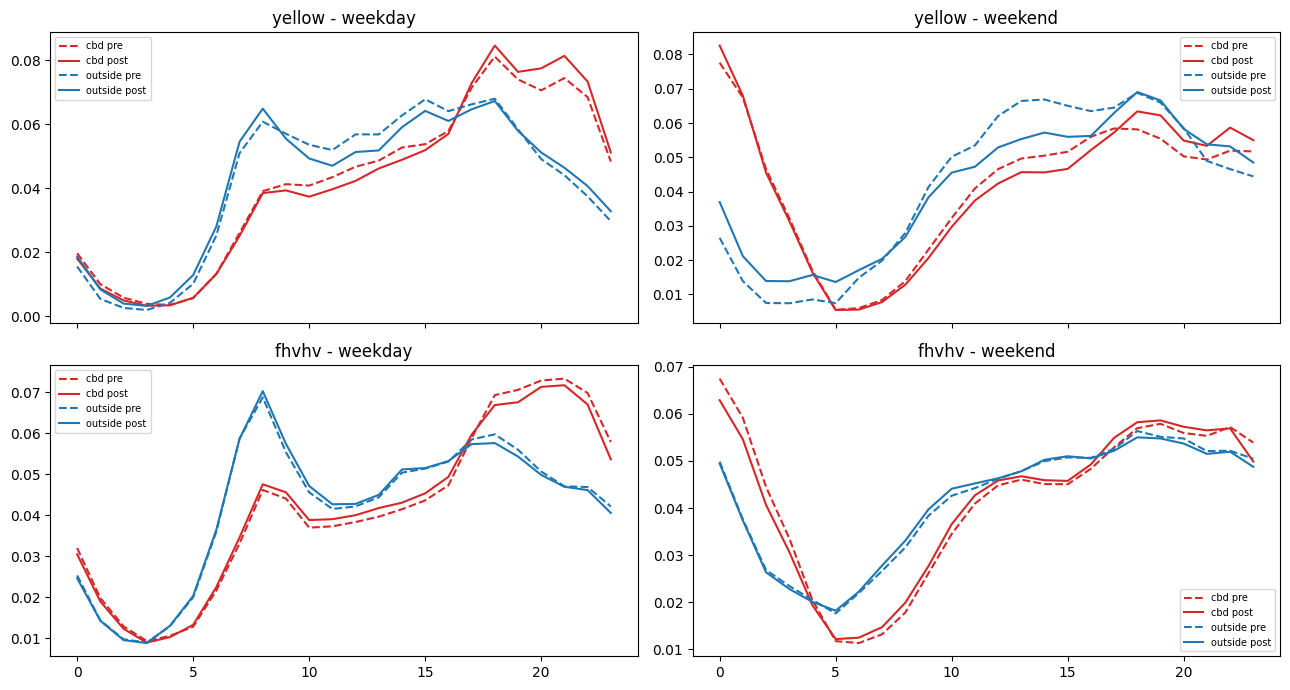

region            cbd  outside
service daytype               
fhvhv   weekday 0.000    0.000
        weekend 0.000    0.000
yellow  weekday 0.001    0.001
        weekend 0.001    0.004

In [21]:
rh = pd.read_csv(f"{DATA}/summary_pickups_by_region_hour.csv")
rh = rh[(rh.dataset == "counts") & rh.service.isin(SERVICES) & rh.region.isin(["cbd", "outside"])]
PRE_M, POST_M = YOY_PRE, YOY_POST     # Feb-Mar 2024 vs Feb-Mar 2025


def hour_share(sub):
    h = sub.groupby("hour").trips.sum().reindex(range(24), fill_value=0)
    return h / h.sum()


js_rows = []
fig, axes = plt.subplots(2, 2, figsize=(13, 7), sharex=True)
for i, s in enumerate(SERVICES):
    for j, dt in enumerate(["weekday", "weekend"]):
        ax = axes[i, j]
        for reg, col in [("cbd", "tab:red"), ("outside", "tab:blue")]:
            sub = rh[(rh.service == s) & (rh.region == reg) & (rh.daytype == dt)]
            a, b = hour_share(sub[sub.ym.isin(PRE_M)]), hour_share(sub[sub.ym.isin(POST_M)])
            ax.plot(a.index, a, color=col, ls="--", label=f"{reg} pre")
            ax.plot(b.index, b, color=col, label=f"{reg} post")
            js_rows.append(dict(service=s, daytype=dt, region=reg, js_divergence=jensenshannon(a, b) ** 2))
        ax.set_title(f"{s} - {dt}")
        ax.legend(fontsize=7)
plt.tight_layout()
plt.savefig("figures/h4_hourly_profiles.png", dpi=150)
plt.show()
pd.DataFrame(js_rows).pivot_table(index=["service", "daytype"], columns="region", values="js_divergence")

#### H4 (extra) – sharper peak windows (7:00–10:30 and 16:30–21:00)
The first H4 test used the toll's own peak (5am–9pm), which covers most of the day. Here peak is only the two commuting rushes, **weekdays 07:00–10:30 and 16:30–21:00**; everything else on weekdays is "not peak". Because 10:30 and 16:30 are half-hours, we need the exact pickup *minute*, which the hourly tables don't have, so this reads the raw parquet files again (DuckDB, cached to `results/h4b_peak_split.csv`).
**Weekends** run as a separate test with their own window. The default is **12:00–21:00** (the midday-to-evening plateau in your hourly weekend plots); change `WEEKEND_PEAK` if you want a different window.

Windows are written as minutes after midnight, start included and end excluded.


In [36]:
import duckdb

RAW_DIR = "../data"
MONTHS = ["2024-10", "2024-11", "2024-12", "2025-01", "2025-02", "2025-03"]
WEEKDAY_PEAK = [(7 * 60, 10 * 60 + 30), (16 * 60 + 30, 21 * 60)]   # 07:00-10:30 and 16:30-21:00
WEEKEND_PEAK = [(12 * 60, 21 * 60)]                                  # 12:00-21:00 (change if you like)
H4_CACHE = "results/h4b_peak_split.csv"


def peak_sql(col, windows):
    mins = f"(hour({col}) * 60 + minute({col}))"
    return "(" + " OR ".join(f"({mins} >= {a} AND {mins} < {b})" for a, b in windows) + ")"


def in_ranges(dts, ranges):
    dts = pd.Series(dts)
    keep = np.zeros(len(dts), dtype=bool)
    for a, b in ranges:
        keep |= ((dts >= a) & (dts <= b)).values
    return keep


if os.path.exists(H4_CACHE):
    raw_h4 = pd.read_csv(H4_CACHE, parse_dates=["date"])
    print("loaded cached table:", raw_h4.shape)
else:
    TS = {"yellow": ("tpep_pickup_datetime", "tpep_dropoff_datetime"), "fhvhv": ("pickup_datetime", "dropoff_datetime")}
    zone_list = ",".join(str(x) for x in sorted(set(cbd_zones) | set(pool_zones)))   # CBD + control pool
    con = duckdb.connect()
    parts = []
    for s in SERVICES:
        pu_ts, do_ts = TS[s]
        for ym in MONTHS:
            path = f"{RAW_DIR}/{s}_tripdata_{ym}.parquet"
            if not os.path.exists(path):
                print("missing file, skipped:", path)
                continue
            names = {r[0].lower(): r[0] for r in con.execute(f"DESCRIBE SELECT * FROM read_parquet('{path}')").fetchall()}
            pu, t0, t1 = names["pulocationid"], names[pu_ts], names[do_ts]
            y, m = int(ym[:4]), int(ym[5:])
            nxt = f"{y + 1}-01-01" if m == 12 else f"{y}-{m + 1:02d}-01"
            col = f'"{t0}"'
            q = f"""
                SELECT '{s}' AS service, CAST({col} AS DATE) AS date, CAST("{pu}" AS INTEGER) AS zone,
                       CASE WHEN dayofweek({col}) IN (0, 6) THEN 'weekend' ELSE 'weekday' END AS daytype,
                       CAST(CASE WHEN dayofweek({col}) IN (0, 6) THEN {peak_sql(col, WEEKEND_PEAK)}
                                 ELSE {peak_sql(col, WEEKDAY_PEAK)} END AS INTEGER) AS is_peak,
                       count(*) AS trips
                FROM read_parquet('{path}')
                WHERE {col} >= TIMESTAMP '{ym}-01' AND {col} < TIMESTAMP '{nxt}'
                  AND "{t1}" > {col} AND "{pu}" IS NOT NULL
                  AND CAST("{pu}" AS INTEGER) IN ({zone_list})
                GROUP BY 2, 3, 4, 5
            """
            parts.append(con.execute(q).df())
            print("done", s, ym)
    raw_h4 = pd.concat(parts, ignore_index=True)
    raw_h4["date"] = pd.to_datetime(raw_h4["date"])
    raw_h4.to_csv(H4_CACHE, index=False)
print(raw_h4.head())

done yellow 2024-10
done yellow 2024-11
done yellow 2024-12
done yellow 2025-01
done yellow 2025-02
done yellow 2025-03
done fhvhv 2024-10
done fhvhv 2024-11
done fhvhv 2024-12
done fhvhv 2025-01
done fhvhv 2025-02
done fhvhv 2025-03
  service       date  zone  daytype  is_peak  trips
0  yellow 2024-10-01   186  weekday        0   1996
1  yellow 2024-10-01    25  weekday        0     30
2  yellow 2024-10-01   130  weekday        0     19
3  yellow 2024-10-01   137  weekday        0    643
4  yellow 2024-10-01   152  weekday        0     45


#### H4 (extra) – the test
For each service and each day type (weekday / weekend), CBD zones vs matched control zones, before vs after, zone and date effects, errors clustered by zone. Three outcomes:
- **peak trips** (count, Poisson): did trips in the peak windows fall?
- **non-peak trips** (count, Poisson): did the rest of the day change?
- **peak share** (peak ÷ all trips per zone-day, weighted least squares): did the *mix* shift? The coefficient is in share units (0.01 = 1 percentage point).
#### If peak falls more than non-peak, the share falls.


In [37]:
def peak_did(service, daytype):
    t, m = setup[service]["treated"], setup[service]["matched"]
    zones = t + m
    r = raw_h4[(raw_h4.service == service) & (raw_h4.daytype == daytype) & raw_h4.zone.isin(zones)]
    dates = np.sort(r.date.unique())
    dates = dates[in_ranges(dates, MAIN_RANGES)]
    idx = pd.MultiIndex.from_product([sorted(zones), dates], names=["zone", "date"])
    pk = r[r.is_peak == 1].groupby(["zone", "date"]).trips.sum().reindex(idx, fill_value=0)
    op = r[r.is_peak == 0].groupby(["zone", "date"]).trips.sum().reindex(idx, fill_value=0)
    base = pd.DataFrame({"peak": pk, "off": op}).reset_index()
    base["treat"] = base.zone.isin(t).astype(int)
    base["post"] = post_d1(base.date)
    base["treat_post"] = base.treat * base.post
    out = []
    for name, col in [("peak trips", "peak"), ("non-peak trips", "off")]:
        d = base.assign(trips_counts=base[col])
        res = fit_poisson(d, ["treat_post"])
        out.append(dict(tidy(res, "treat_post", f"{service} {daytype}: {name}", d.zone.nunique()), kind="count"))
    d = base.assign(total=base.peak + base.off)
    d = d[d.total > 0].copy()
    d["peak_share"] = d.peak / d.total
    res = fit_wls(d, "peak_share", ["treat_post"], "total")
    r_share = tidy(res, "treat_post", f"{service} {daytype}: peak share", d.zone.nunique(), pct=False)
    cbd_pre = d[(d.treat == 1) & (d.post == 0)]
    r_share["cbd_pre_peak_share"] = cbd_pre.peak.sum() / cbd_pre.total.sum()
    r_share["kind"] = "share"
    out.append(r_share)
    return out, base


h4b, h4b_data = [], {}
for s in SERVICES:
    for dt in ["weekday", "weekend"]:
        o, b = peak_did(s, dt)
        h4b += o
        h4b_data[(s, dt)] = b
h4b = pd.DataFrame(h4b)
h4b[["label", "pct", "pct_low", "pct_high", "coef", "ci_low", "ci_high", "p", "cbd_pre_peak_share", "clusters"]]

,label,pct,pct_low,pct_high,coef,ci_low,ci_high,p,cbd_pre_peak_share,clusters
0,yellow weekday: peak trips,1.930,-5.237,9.639,0.019,-0.054,0.092,0.607,NaN,69
1,yellow weekday: non-peak trips,-3.398,-9.020,2.572,-0.035,-0.095,0.025,0.259,NaN,69
2,yellow weekday: peak share,NaN,NaN,NaN,0.012,0.005,0.020,0.001,0.447,69
3,yellow weekend: peak trips,-0.219,-7.593,7.744,-0.002,-0.079,0.075,0.955,NaN,69
4,yellow weekend: non-peak trips,-2.858,-12.396,7.719,-0.029,-0.132,0.074,0.582,NaN,69
5,yellow weekend: peak share,NaN,NaN,NaN,0.000,-0.009,0.010,0.973,0.482,69
6,fhvhv weekday: peak trips,-5.066,-6.114,-4.007,-0.052,-0.063,-0.041,0.000,NaN,89
7,fhvhv weekday: non-peak trips,-9.870,-11.507,-8.204,-0.104,-0.122,-0.086,0.000,NaN,89
8,fhvhv weekday: peak share,NaN,NaN,NaN,0.013,0.009,0.016,0.000,0.422,89
9,fhvhv weekend: peak trips,-0.117,-2.034,1.837,-0.001,-0.021,0.018,0.905,NaN,89


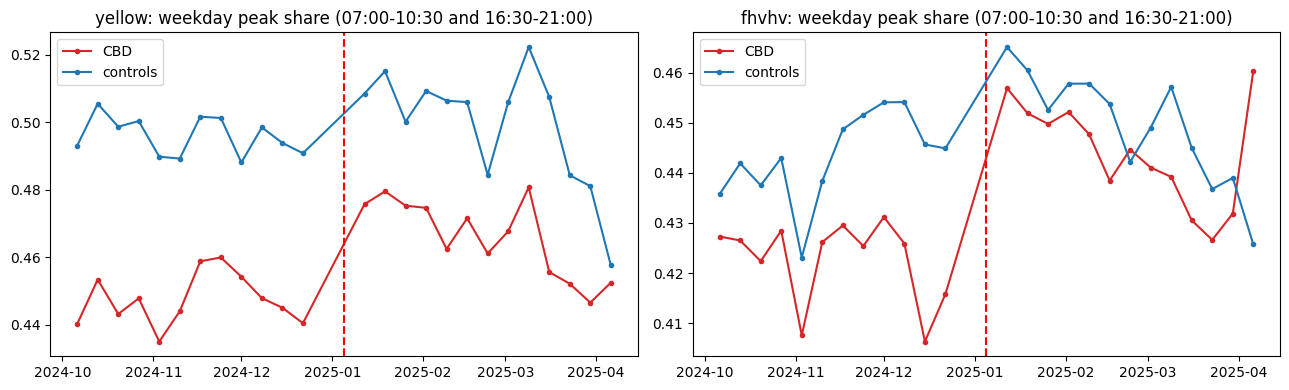

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, s in zip(axes, SERVICES):
    b = h4b_data[(s, "weekday")]
    w = b.groupby(["treat", pd.Grouper(key="date", freq="W")])[["peak", "off"]].sum()
    w["share"] = w.peak / (w.peak + w.off)
    for tr, lab, col in [(1, "CBD", "tab:red"), (0, "controls", "tab:blue")]:
        x = w.loc[tr]
        x = x[(x.peak + x.off) > 0]
        ax.plot(x.index, x.share, marker="o", ms=3, color=col, label=lab)
    ax.axvline(START, color="red", ls="--")
    ax.set_title(f"{s}: weekday peak share (07:00-10:30 and 16:30-21:00)")
    ax.legend()
plt.tight_layout()
plt.savefig("figures/h4b_weekly_peak_share.png", dpi=150)
plt.show()

# H5 – Trip duration per mile
**Question:** did seconds per mile for trips starting in the CBD change relative to controls?
**Data:** `summary_zone_daily.csv` → `secs_strict`, `miles_strict`, `trips_strict` (the strict version removes impossible durations and speeds).
**Method:** `log(seconds per mile)` per zone-day, WLS weighted by miles, with `log(average trip length)` as a control so a change in trip mix does not look like a change in speed. Run for all hours, then peak and off-peak separately.
*Limit:* only the pickup zone is known, not the route, so trips that start outside the CBD and drive through it are not captured.

In [22]:
h5 = []
for s in SERVICES:
    for per in [None, "peak", "offpeak"]:
        df = did_panel(s, setup[s]["treated"], setup[s]["matched"], MAIN_RANGES, period=per)
        df = df[(df.miles_strict > 0) & (df.trips_strict > 0)].copy()
        df["log_spm"] = np.log(df.secs_strict / df.miles_strict)
        df["log_avg_miles"] = np.log(df.miles_strict / df.trips_strict)
        res = fit_wls(df, "log_spm", ["treat_post", "log_avg_miles"], "miles_strict")
        lab = f"H5 {s} ({per or 'all hours'})"
        r = tidy(res, "treat_post", lab, df.zone.nunique())
        h5.append(r)
        if per is None:
            rows.append(dict(r, hyp="H5", service=s, primary=True))
pd.DataFrame(h5)[["label", "pct", "pct_low", "pct_high", "p", "n", "clusters"]]

,label,pct,pct_low,pct_high,p,n,clusters
0,H5 yellow (all hours),-5.219,-7.186,-3.210,0.000,11101,69
1,H5 yellow (peak),-6.365,-8.229,-4.464,0.000,11091,69
2,H5 yellow (offpeak),-6.373,-7.690,-5.038,0.000,10921,69
3,H5 fhvhv (all hours),-6.462,-7.242,-5.677,0.000,14329,89
4,H5 fhvhv (peak),-7.184,-7.989,-6.372,0.000,14329,89
5,H5 fhvhv (offpeak),-5.934,-6.750,-5.110,0.000,14325,89


### H5 – what the hourly picture looks like
Seconds per mile by hour for CBD pickups, Feb–Mar 2024 vs Feb–Mar 2025 (weekdays). From the region-hour file, so no confidence intervals; use it to see *when* any change happens.

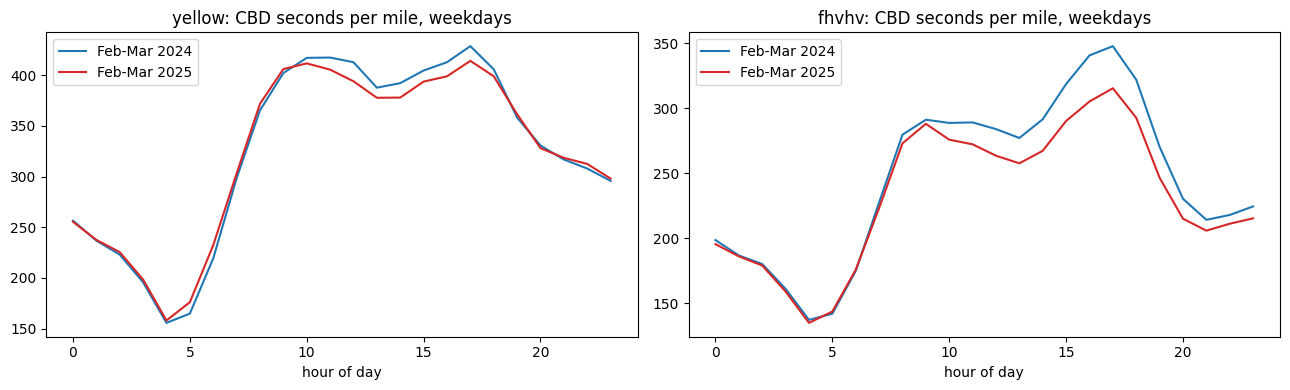

In [23]:
rs = pd.read_csv(f"{DATA}/summary_pickups_by_region_hour.csv")
rs = rs[(rs.dataset == "strict") & rs.service.isin(SERVICES) & (rs.region == "cbd") & (rs.daytype == "weekday")]
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=False)
for ax, s in zip(axes, SERVICES):
    sub = rs[rs.service == s]
    for lab, months, col in [("Feb-Mar 2024", PRE_M, "tab:blue"), ("Feb-Mar 2025", POST_M, "tab:red")]:
        x = sub[sub.ym.isin(months)]
        w = x.groupby("hour").apply(lambda g: np.average(g.sec_per_mile, weights=g.trips))
        ax.plot(w.index, w.values, color=col, label=lab)
    ax.set_title(f"{s}: CBD seconds per mile, weekdays")
    ax.set_xlabel("hour of day")
    ax.legend()
plt.tight_layout()
plt.savefig("figures/h5_hourly_sec_per_mile.png", dpi=150)
plt.show()

# H6 – Passenger charges
**Question:** did the fee raise what passengers pay without a matching rise in the underlying fare?
**Data:** `summary_zone_daily.csv` → `base_fare_strict`, `trips_strict`, `miles_strict`, `n_fee_trips_strict`, `cbd_fee_strict`; `summary_pickups_by_region_hour.csv` → `avg_charge_ex_tip`, `avg_cbd_fee`.
**Method:** (1) DiD on `log(average base fare per trip)`, controlling for trip length. A value near zero means the underlying fare did not rise in the CBD relative to controls. (2) How often the fee was charged and how big it is relative to the full charge (descriptive, post-policy). (3) Change in total charge from the region file (descriptive, year-on-year; a zone-level test needs one more export). A *negative* base-fare effect is not a mistake: if trips are faster (H5), time-based fare parts fall too. The year-on-year charge table further down does **not** control for trip length while this regression does, so the two can differ: if CBD trips got longer, raw fares rise even when the fare for a given distance falls.

In [24]:
h6 = []
for s in SERVICES:
    df = did_panel(s, setup[s]["treated"], setup[s]["matched"], MAIN_RANGES)
    df = df[(df.trips_strict > 0) & (df.miles_strict > 0)].copy()
    df["log_avg_base"] = np.log(df.base_fare_strict / df.trips_strict)
    df["log_avg_miles"] = np.log(df.miles_strict / df.trips_strict)
    res = fit_wls(df, "log_avg_base", ["treat_post", "log_avg_miles"], "trips_strict")
    r = tidy(res, "treat_post", f"H6 {s} (avg base fare per trip)", df.zone.nunique())
    h6.append(r)
    rows.append(dict(r, hyp="H6", service=s, primary=True))
pd.DataFrame(h6)[["label", "pct", "pct_low", "pct_high", "p", "n", "clusters"]]

,label,pct,pct_low,pct_high,p,n,clusters
0,H6 yellow (avg base fare per trip),-4.053,-5.047,-3.050,0.000,11101,69
1,H6 fhvhv (avg base fare per trip),-5.791,-6.378,-5.200,0.000,14329,89


In [25]:
# How often was the fee charged, by region and month (share of trips with fee > 0)?
fee = z[z.service.isin(SERVICES) & z.region.isin(["cbd", "buffer", "outside"]) & ~z.is_airport & (z.date >= "2025-01-01")]
fee = fee.assign(ym=fee.date.dt.strftime("%Y-%m"))
inc = fee.groupby(["service", "region", "ym"])[["n_fee_trips_strict", "trips_strict"]].sum()
inc["share_with_fee"] = inc.n_fee_trips_strict / inc.trips_strict
inc["avg_fee_per_trip"] = fee.groupby(["service", "region", "ym"]).cbd_fee_strict.sum() / inc.trips_strict
inc[["share_with_fee", "avg_fee_per_trip"]].unstack(2)

share_with_fee                 avg_fee_per_trip                
ym                     2025-01 2025-02 2025-03          2025-01 2025-02 2025-03
service region                                                                 
fhvhv   buffer           0.543   0.618   0.624            0.814   0.928   0.936
        cbd              0.884   0.993   0.993            1.326   1.489   1.489
        outside          0.080   0.094   0.092            0.120   0.142   0.137
yellow  buffer           0.453   0.519   0.545            0.340   0.390   0.409
        cbd              0.886   0.994   0.994            0.665   0.746   0.746
        outside          0.235   0.262   0.267            0.177   0.197   0.201

In [26]:
# Total charge (fare + all fees, no tips): CBD vs outside, Feb-Mar 2024 vs Feb-Mar 2025, from the region-hour file.
# "outside" in this file includes airports, so read this as a rough guide only.
rc = pd.read_csv(f"{DATA}/summary_pickups_by_region_hour.csv")
rc = rc[(rc.dataset == "strict") & rc.service.isin(SERVICES) & rc.region.isin(["cbd", "outside"])]
rc = rc.assign(period=np.where(rc.ym.isin(PRE_M), "pre", np.where(rc.ym.isin(POST_M), "post", "skip")))
rc = rc[rc.period != "skip"]
out = (rc.groupby(["service", "region", "period"])
         .apply(lambda g: pd.Series({"avg_charge": np.average(g.avg_charge_ex_tip, weights=g.trips),
                                     "avg_base_fare": np.average(g.avg_base_fare, weights=g.trips),
                                     "avg_cbd_fee": np.average(g.avg_cbd_fee, weights=g.trips)}))
         .unstack("period"))
tab = pd.DataFrame({
    "charge_change_$": out[("avg_charge", "post")] - out[("avg_charge", "pre")],
    "base_fare_change_$": out[("avg_base_fare", "post")] - out[("avg_base_fare", "pre")],
    "avg_fee_post_$": out[("avg_cbd_fee", "post")],
})
tab["charge_change_%"] = (out[("avg_charge", "post")] / out[("avg_charge", "pre")] - 1) * 100
tab["base_fare_change_%"] = (out[("avg_base_fare", "post")] / out[("avg_base_fare", "pre")] - 1) * 100
tab

charge_change_$  base_fare_change_$  avg_fee_post_$  charge_change_%  base_fare_change_%
service region                                                                                           
fhvhv   cbd                4.787               3.141           1.489           12.968              10.744
        outside            1.030               0.904           0.158            3.781               3.912
yellow  cbd                0.371              -0.247           0.746            1.747              -1.530
        outside           -1.631              -0.986           0.234           -4.727              -3.544

# Multiple-testing adjustment
We ran many main tests (H1, H2, H3, H4, H5, H6 for each service). With many tests, some will look significant by chance, so we report adjusted p-values: **Holm** (strict) and **Benjamini-Hochberg** (controls the share of false discoveries). Placebo, pre-trend and sensitivity runs are diagnostics and are not part of this family.

In [27]:
main = pd.DataFrame([r for r in rows if r.get("primary")])
main["p_holm"] = multipletests(main.p, method="holm")[1]
main["p_bh"] = multipletests(main.p, method="fdr_bh")[1]
main["significant_5%_holm"] = main.p_holm < 0.05
cols = ["hyp", "service", "label", "pct", "pct_low", "pct_high", "coef", "ci_low", "ci_high", "p", "p_holm", "p_bh", "significant_5%_holm", "n", "clusters"]
main = main[[c for c in cols if c in main.columns]]
main.to_csv("results/h1_h6_main.csv", index=False)
main

,hyp,service,label,pct,pct_low,pct_high,coef,ci_low,ci_high,p,p_holm,p_bh,significant_5%_holm,n,clusters
0,H1,yellow,"H1 yellow (CBD pickups, matched controls)",-0.596,-7.623,6.965,-0.006,-0.079,0.067,0.873,1.000,0.873,False,11109,69
1,H1,fhvhv,"H1 fhvhv (CBD pickups, matched controls)",-7.233,-8.421,-6.030,-0.075,-0.088,-0.062,0.000,0.000,0.000,True,14329,89
2,H2,yellow,H2 yellow (buffer pickups),-4.350,-10.881,2.660,-0.044,-0.115,0.026,0.218,0.653,0.266,False,2576,16
3,H2,fhvhv,H2 fhvhv (buffer pickups),-5.831,-10.052,-1.412,-0.060,-0.106,-0.014,0.010,0.051,0.016,False,4186,26
4,H3,difference,H3 yellow minus fhvhv (log points),NaN,NaN,NaN,0.069,-0.005,0.143,0.068,0.270,0.093,False,25438,103
5,H4,yellow,"H4 yellow (peak share, share units)",NaN,NaN,NaN,0.002,-0.007,0.010,0.678,1.000,0.745,False,11104,69
6,H4,fhvhv,"H4 fhvhv (peak share, share units)",NaN,NaN,NaN,0.017,0.012,0.021,0.000,0.000,0.000,True,14329,89
7,H5,yellow,H5 yellow (all hours),-5.219,-7.186,-3.210,-0.054,-0.075,-0.033,0.000,0.000,0.000,True,11101,69
8,H5,fhvhv,H5 fhvhv (all hours),-6.462,-7.242,-5.677,-0.067,-0.075,-0.058,0.000,0.000,0.000,True,14329,89
9,H6,yellow,H6 yellow (avg base fare per trip),-4.053,-5.047,-3.050,-0.041,-0.052,-0.031,0.000,0.000,0.000,True,11101,69


## What to send back / write down
1. The final table above (`results/h1_h6_main.csv`).
2. The figures in `figures/` (event studies, placebo histogram, hourly profiles).
3. `results/h1_sensitivity.csv`.

**Reading guide:** `pct` is a % change relative to control zones (H1, H2, H3 per service, H5, H6). For H4 the coefficient is a change in peak share (0.01 = 1 percentage point). Always report the 95% interval and whether the pre-trend test and placebo tests look clean before you interpret an effect as caused by the policy.